# `relay_mcs_resource_eval` — analysis

Skel auto-generated by `_build_notebook.py`. Cells are filled in once
phase1/2/2b/3 CSVs are in `results_relay_mcs_resource_eval/`.


In [1]:
import json, math, os, sys
from collections import defaultdict
from pathlib import Path
from statistics import mean, median, stdev

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['figure.figsize'] = (8, 5)
mpl.rcParams['figure.dpi'] = 110
mpl.rcParams['axes.grid'] = True
mpl.rcParams['grid.alpha'] = 0.3


## 1. Load phase outputs

In [2]:
RES_ROOT = Path(os.environ.get('RMRE_RESULTS',
    Path.cwd() / 'results_relay_mcs_resource_eval'))
p1_dir  = RES_ROOT / 'phase1'
p2_dir  = RES_ROOT / 'phase2'
p2b_dir = RES_ROOT / 'phase2b'
p3_dir  = RES_ROOT / 'phase3'

phase1_surface  = pd.read_csv(p1_dir  / 'phase1_surface.csv')  if (p1_dir  / 'phase1_surface.csv').exists()  else None
phase1_mstar    = pd.read_csv(p1_dir  / 'phase1_mstar.csv')    if (p1_dir  / 'phase1_mstar.csv').exists()    else None
phase1_baseline = pd.read_csv(p1_dir  / 'phase1_baseline.csv') if (p1_dir  / 'phase1_baseline.csv').exists() else None
phase2_sweep    = pd.read_csv(p2_dir  / 'phase2_sweep.csv')    if (p2_dir  / 'phase2_sweep.csv').exists()    else None
phase2b_sweep   = pd.read_csv(p2b_dir / 'phase2b_sweep.csv')   if (p2b_dir / 'phase2b_sweep.csv').exists()   else None
phase3_compare  = pd.read_csv(p3_dir  / 'phase3_compare.csv')  if (p3_dir  / 'phase3_compare.csv').exists()  else None
for name, df in [('phase1_surface', phase1_surface), ('phase1_mstar', phase1_mstar),
                 ('phase1_baseline', phase1_baseline), ('phase2_sweep', phase2_sweep),
                 ('phase2b_sweep', phase2b_sweep), ('phase3_compare', phase3_compare)]:
    print(f'{name}: {"OK, " + str(len(df)) + " rows" if df is not None else "MISSING"}')


phase1_surface: OK, 588 rows
phase1_mstar: OK, 49 rows
phase1_baseline: OK, 7 rows
phase2_sweep: OK, 350 rows
phase2b_sweep: OK, 140 rows
phase3_compare: OK, 70 rows


## 2. R-A — PRR(MCS, distance) surface

`P_hit(i, m, pair) = Pr[PRR_i(m) ≥ target]`, target = 0.99.
`m*_i(pair) = max{ m : P_hit ≥ 0.95 }`, else `best` tail PRR (OP3).
`mcsBaseline(pair) = m*_7(pair)`.

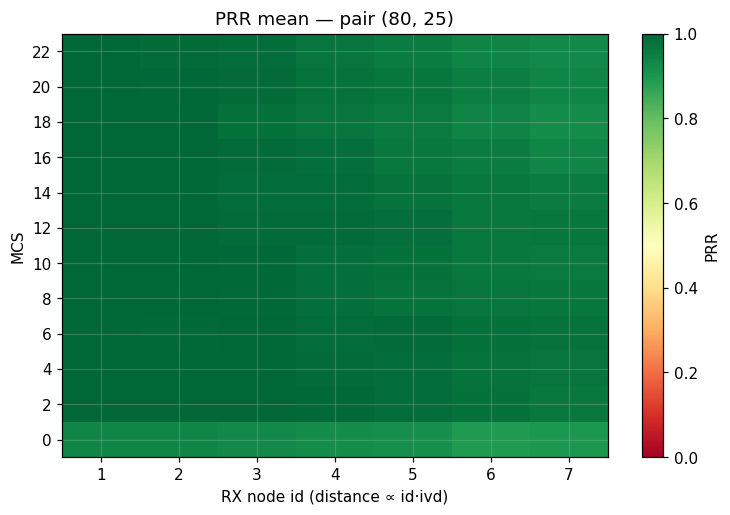

  pair=(80,25)  m*_1=22  m*_7=6  spread=+16
  pair=(90,27)  m*_1=22  m*_7=2  spread=+20
  pair=(100,29)  m*_1=22  m*_7=2  spread=+20
  pair=(110,32)  m*_1=22  m*_7=2  spread=+20
  pair=(120,34)  m*_1=22  m*_7=2  spread=+20
  pair=(130,37)  m*_1=22  m*_7=4  spread=+18
  pair=(140,39)  m*_1=20  m*_7=4  spread=+16


In [3]:
# Placeholder: filled in after Phase 1 completes.
if phase1_surface is not None and phase1_mstar is not None:
    # heatmap of PRR vs (MCS, rx) for one (speed, ivd) pair
    pair = phase1_surface[['speed','ivd']].drop_duplicates().iloc[0]
    sub = phase1_surface[(phase1_surface.speed==pair.speed) & (phase1_surface.ivd==pair.ivd)]
    pivot = sub.pivot(index='mcs', columns='rx_node_id', values='prr_mean')
    fig, ax = plt.subplots()
    im = ax.imshow(pivot.values, aspect='auto', origin='lower', cmap='RdYlGn', vmin=0, vmax=1)
    ax.set_yticks(range(len(pivot.index)));  ax.set_yticklabels(pivot.index)
    ax.set_xticks(range(len(pivot.columns))); ax.set_xticklabels(pivot.columns)
    ax.set_xlabel('RX node id (distance ∝ id·ivd)'); ax.set_ylabel('MCS')
    ax.set_title(f'PRR mean — pair ({pair.speed}, {pair.ivd})')
    fig.colorbar(im, ax=ax, label='PRR')
    plt.show()
    # m*_i per (pair, rx) and spread gate
    ms = phase1_mstar
    pairs = ms[['speed','ivd']].drop_duplicates().sort_values(['speed','ivd'])
    for _, row in pairs.iterrows():
        m1 = ms[(ms.speed==row.speed)&(ms.ivd==row.ivd)&(ms.rx_node_id==1)].m_star.iloc[0]
        m7 = ms[(ms.speed==row.speed)&(ms.ivd==row.ivd)&(ms.rx_node_id==7)].m_star.iloc[0]
        print(f'  pair=({row.speed},{row.ivd})  m*_1={m1}  m*_7={m7}  spread={m1-m7:+d}')
else:
    print('Phase 1 data not yet available; rerun after Phase 1 completes.')


## 3. R-B — relay selection frontier

Per pair, plot PSR, storm_ratio, |PRR_hop1−PRR_hop2|, latency, total resource
vs relay node r ∈ {2..6}. r* = argmin total resource subject to PSR ≥ target,
storm-free, |balance| ≤ 0.02.

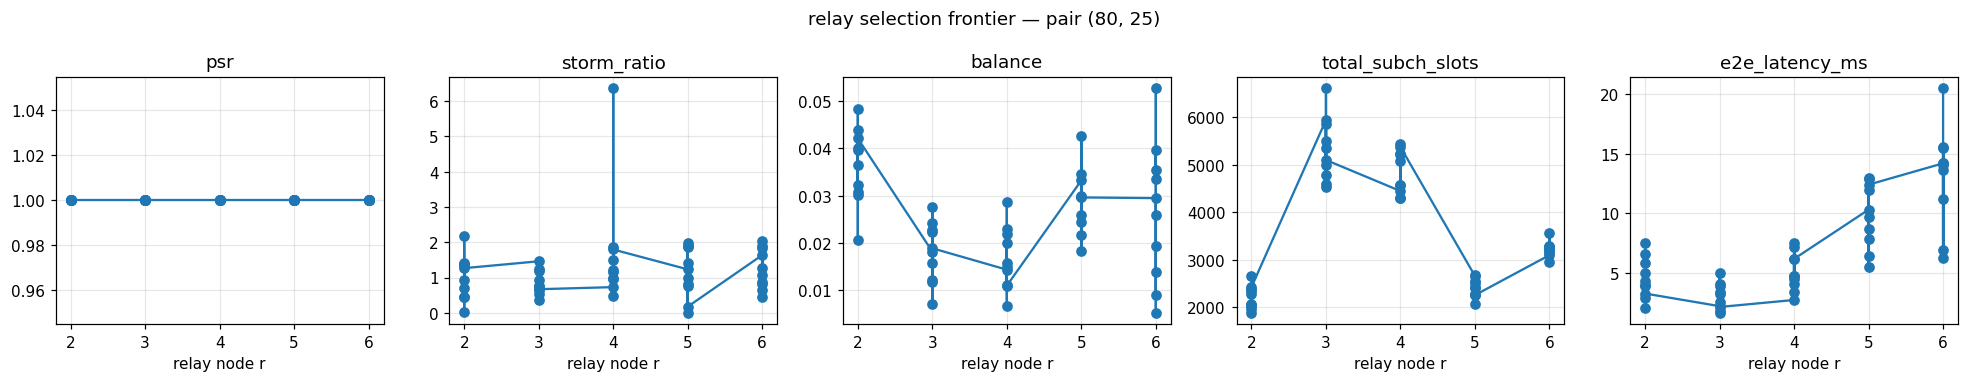

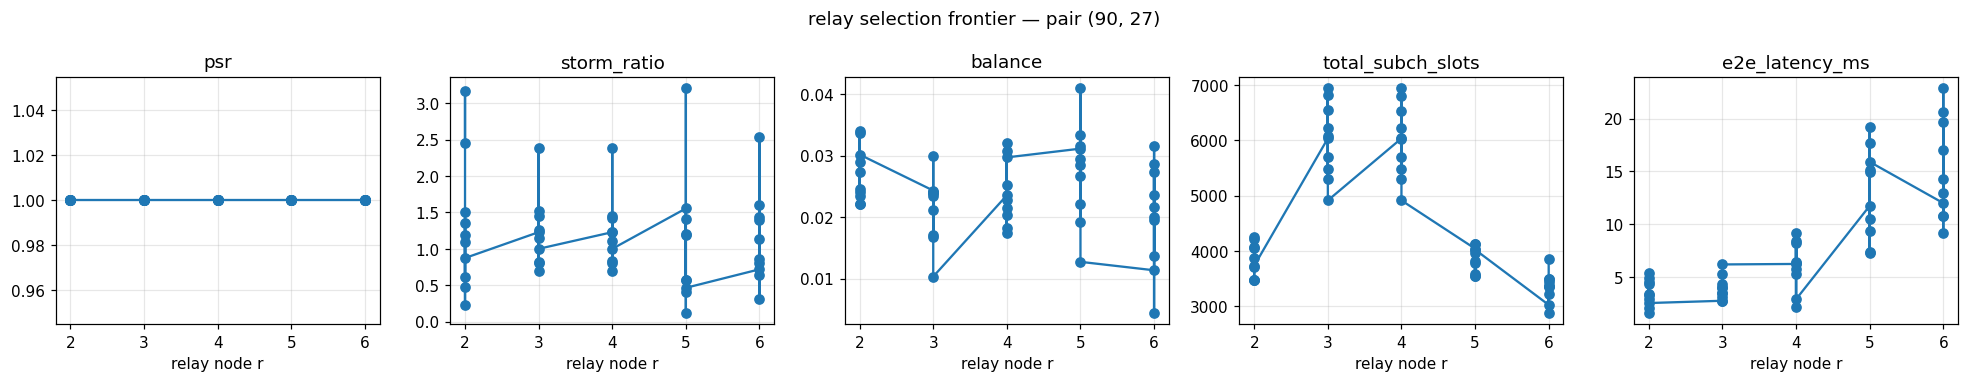

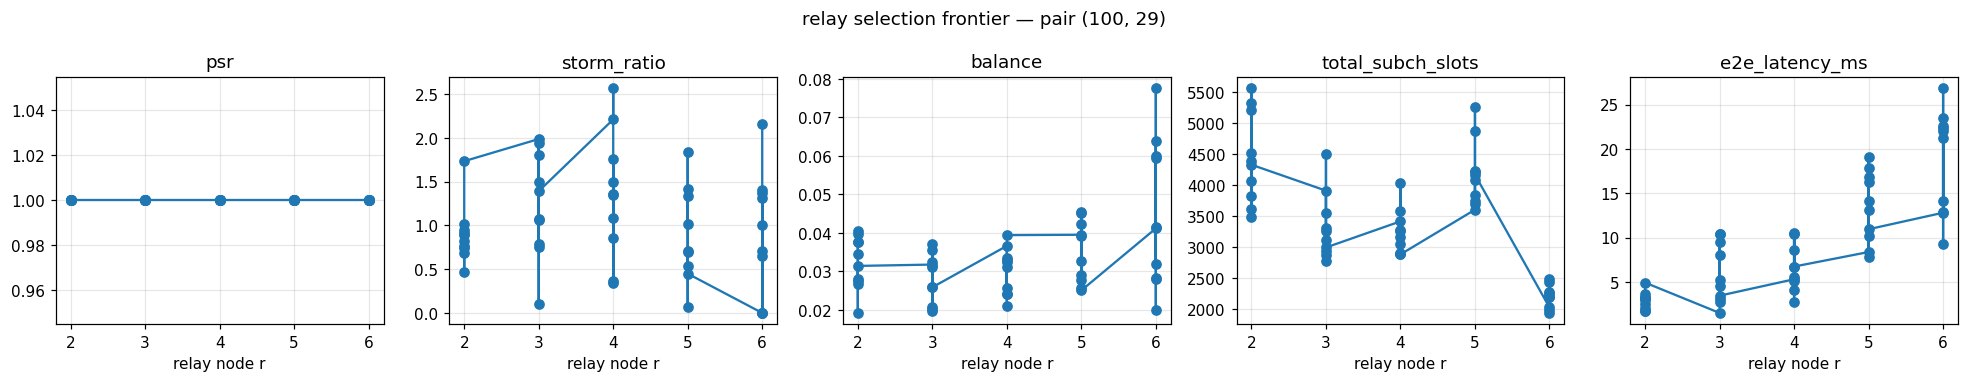

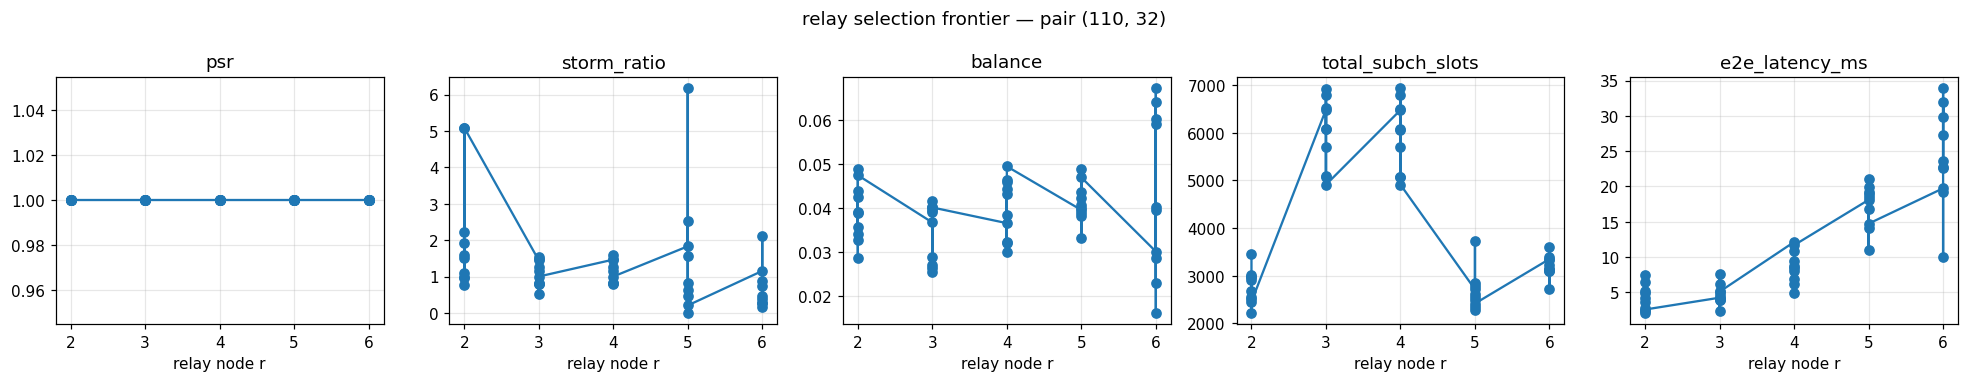

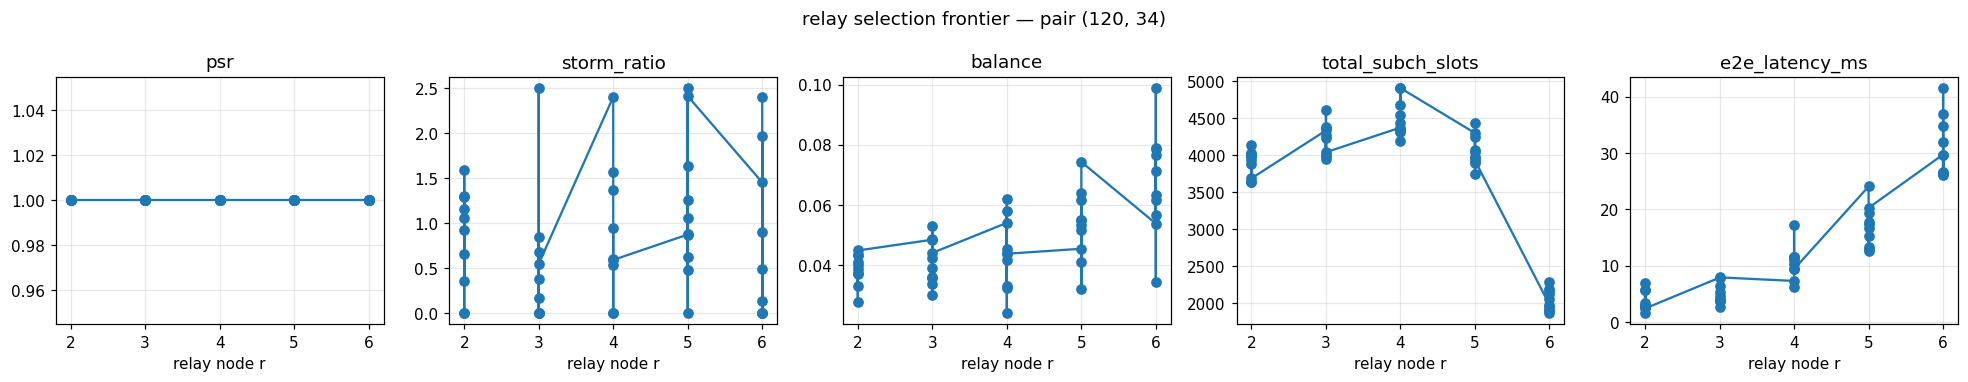

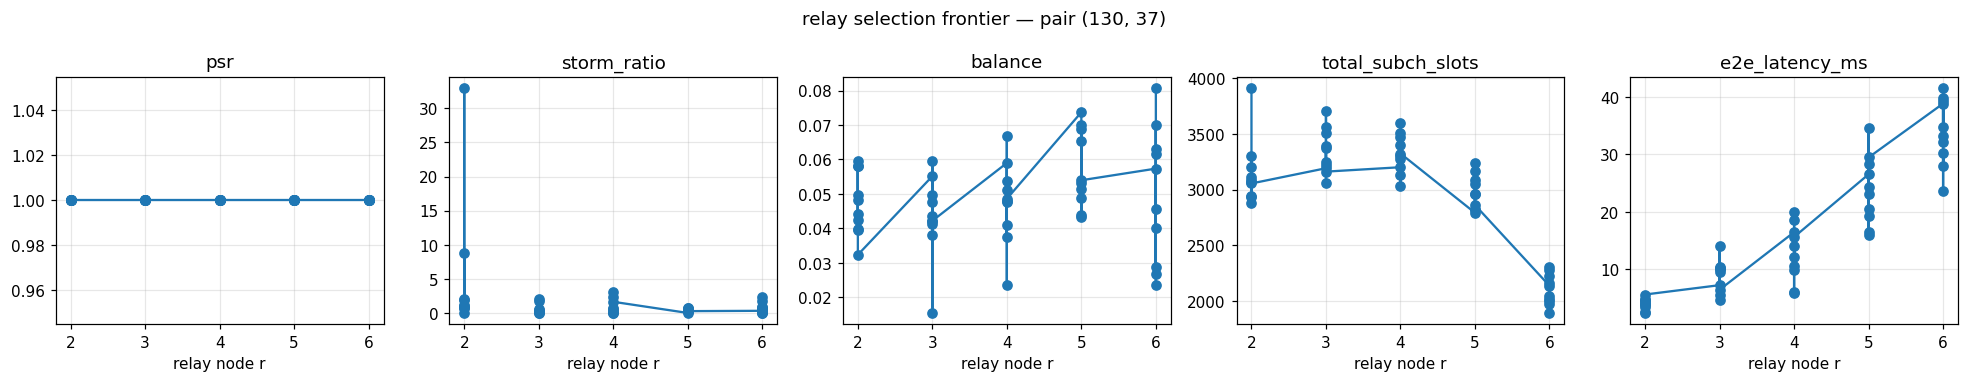

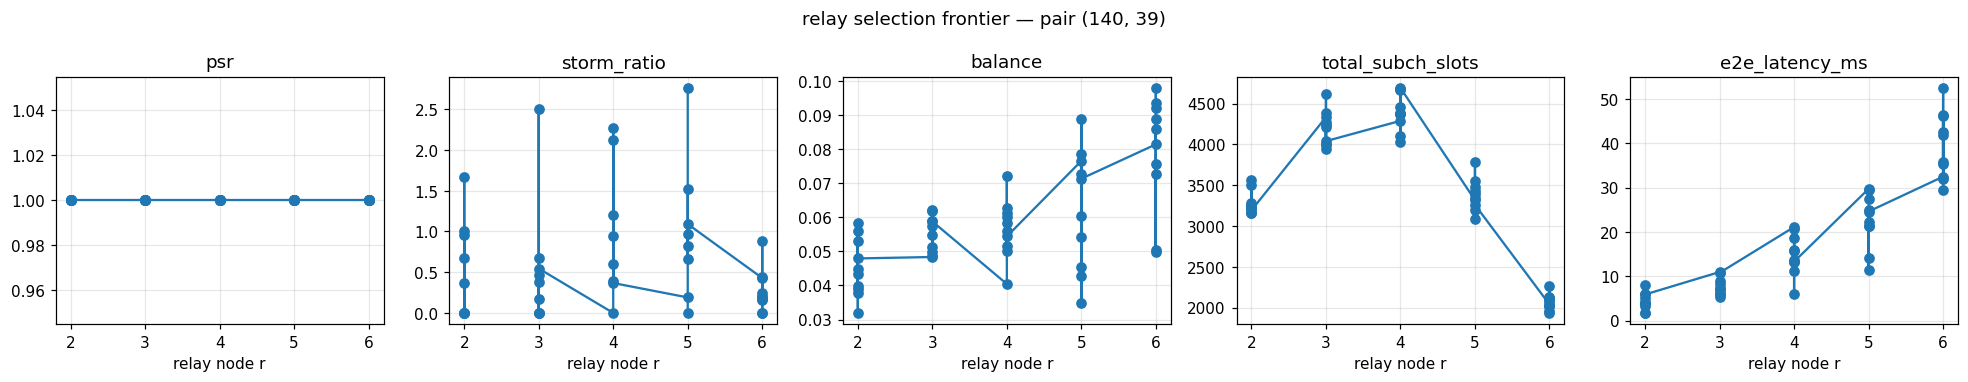

In [4]:
# Placeholder: filled in after Phase 2.
if phase2_sweep is not None:
    for (speed, ivd), grp in phase2_sweep.groupby(['speed','ivd']):
        fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))
        for ax, col in zip(axes, ['psr','storm_ratio','balance','total_subch_slots','e2e_latency_ms']):
            ax.plot(grp.relay, grp[col], 'o-')
            ax.set_title(col); ax.set_xlabel('relay node r')
        fig.suptitle(f'relay selection frontier — pair ({speed}, {ivd})')
        plt.tight_layout(); plt.show()
else:
    print('Phase 2 data not yet available; rerun after Phase 2 completes.')


## 4. R-C — relay latency model

`latency_r = f(dist(0,r), mcsHop1, dist(r,7), mcsHop2, reTX)`.
Decompose into hop1, relay_proc, hop2 and fit a linear model.

In [5]:
# Placeholder: fit latency regression after Phase 2/3.
if phase2_sweep is not None and 'hop1_ms' in phase2_sweep.columns:
    # fit latency = a*dist01 + b*dist17 + c*mcs1 + d*mcs2 + e
    from sklearn.linear_model import LinearRegression
    df = phase2_sweep.dropna(subset=['hop1_ms','hop2_ms','e2e_ms'])
    df['dist01'] = df.relay * df.ivd
    df['dist17'] = (7 - df.relay) * df.ivd
    X = df[['dist01','dist17','mcsHop1','mcsHop2']].values
    for tgt in ['hop1_ms','hop2_ms','e2e_ms']:
        m = LinearRegression().fit(X, df[tgt])
        print(f'  {tgt} = {m.coef_} @ X + {m.intercept_:.2f}  R^2={m.score(X, df[tgt]):.3f}')
else:
    print('Phase 2 latency columns not yet available.')


Phase 2 latency columns not yet available.


## 5. R-D — storm / MCD threshold

At r*, sweep MCD ∈ {(r*−1), r*, (r*+1), (r*+2)} · ivd.
Locate the smallest MCD that is hop-2-covering, storm-free, and balanced.

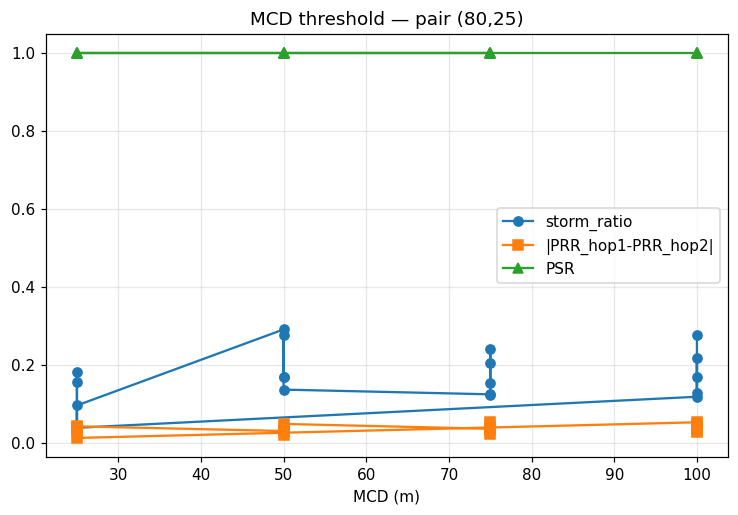

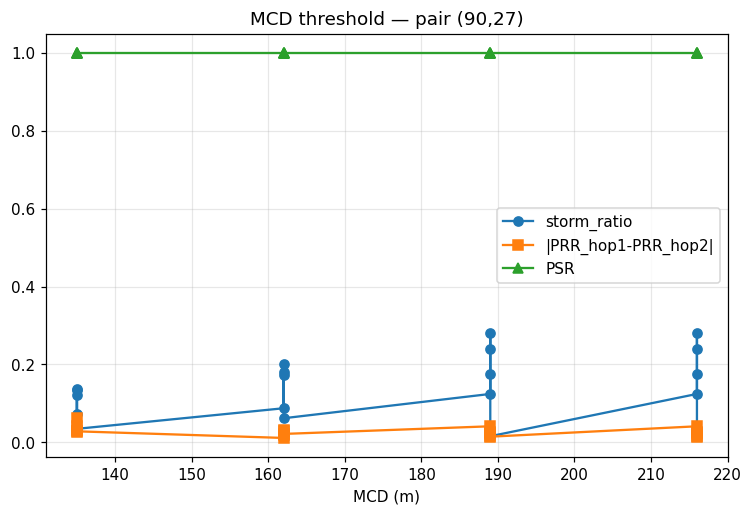

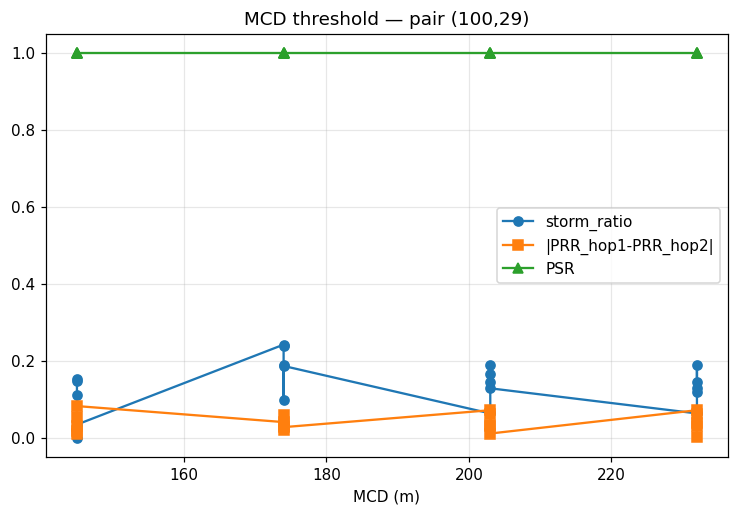

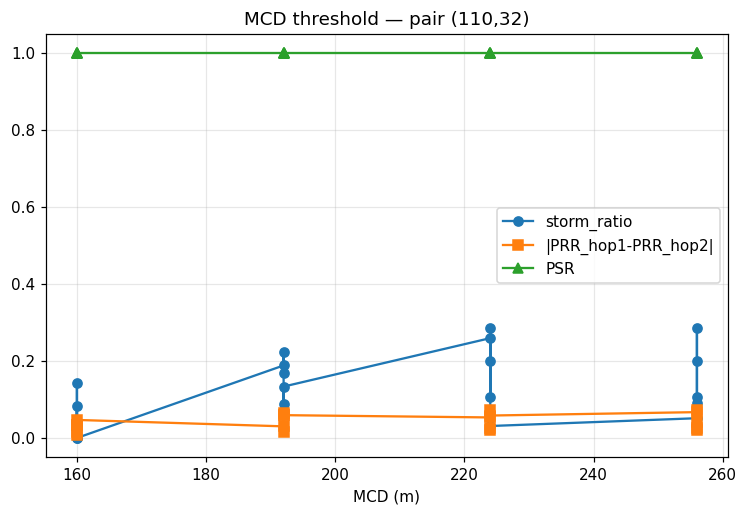

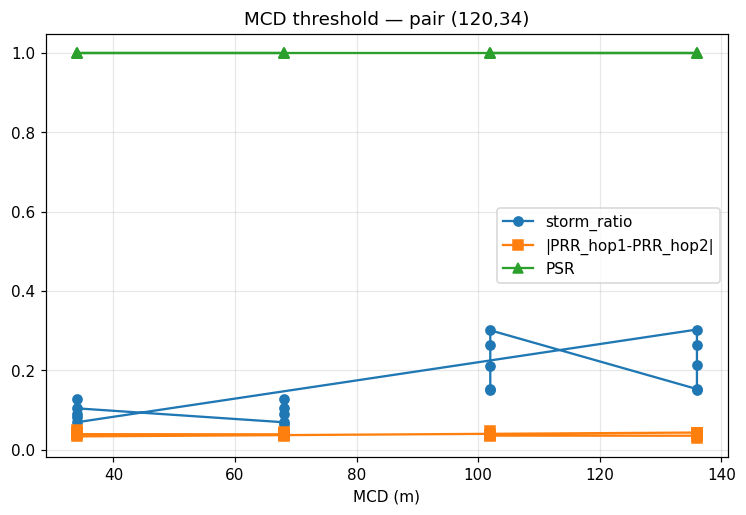

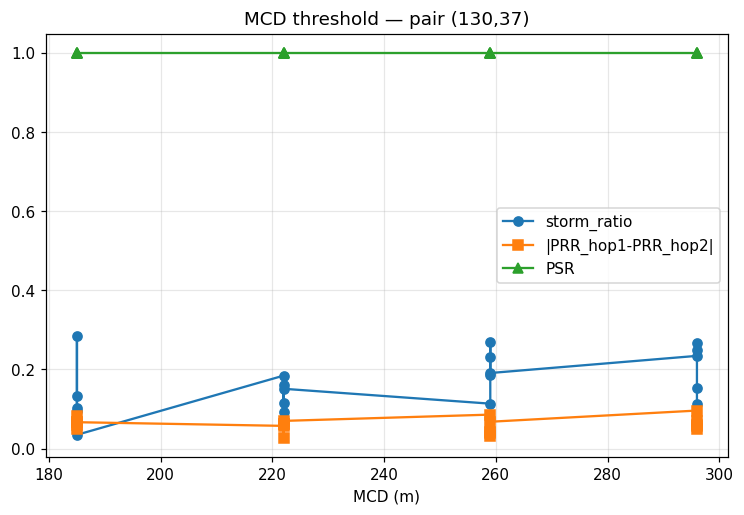

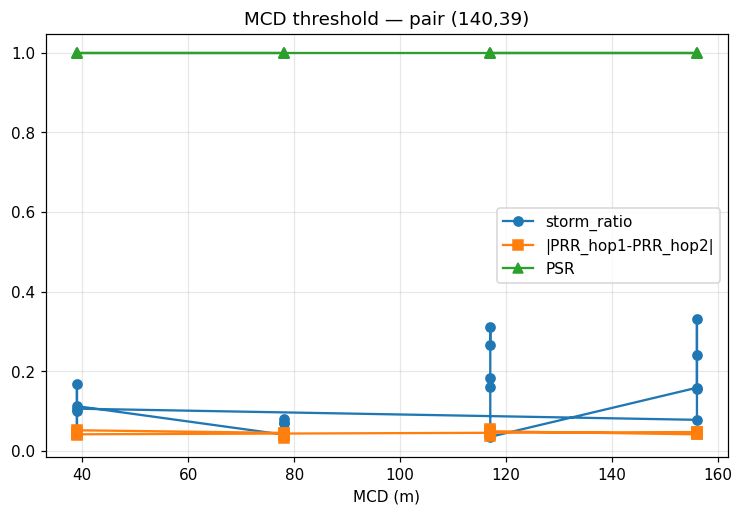

In [6]:
# Placeholder: filled in after Phase 2b.
if phase2b_sweep is not None:
    for (speed, ivd), grp in phase2b_sweep.groupby(['speed','ivd']):
        fig, ax = plt.subplots()
        ax.plot(grp.mcd, grp.storm_ratio, 'o-', label='storm_ratio')
        ax.plot(grp.mcd, grp.balance,    's-', label='|PRR_hop1-PRR_hop2|')
        ax.plot(grp.mcd, grp.psr,        '^-', label='PSR')
        ax.set_xlabel('MCD (m)'); ax.set_title(f'MCD threshold — pair ({speed},{ivd})')
        ax.legend(); plt.show()
else:
    print('Phase 2b data not yet available.')


## 6. H1-H4 verdict — head-to-head

**H1** resource win: relay total subch-slots < baseline (resource_ratio < 1).
**H2** reliability ≥: relay tail & mean PRR ≥ baseline (within 0.5% slack).
**H3** latency ≤: relay PIR & AoI ≤ baseline (within 1ms / same).
**H4** PSR gate: win holds only where PSR ≥ target.

Caveats:
* `prr_worst` is the **per-window minimum** across RX nodes (the truly
  worst case, not the per-RX mean across windows).
* `total_subch_slots` is from `psschTxUeMac` (includes retx) — the
  paired comparison is internally consistent, but absolute values
  differ from the kpi CSV `subch_slots_used` (which excludes retx).
* Wilcoxon paired by seed; **n = 10 seeds per pair**.

**Pre-registered acceptance:** H1 passes iff relay ratio < 1 on ≥ 5/7
pairs (paired-by-seed, p < 0.05). The bar for H2/H3 is similar.


  total_subch_slots: median diff = +2061.000  Wilcoxon p = 0.0000
  prr_worst: median diff = -0.028  Wilcoxon p = 0.0282
  prr_mean: median diff = -0.003  Wilcoxon p = 0.0002
  pir_p95_ms: median diff = +0.240  Wilcoxon p = 0.0027
  aoi_peak_ms: median diff = +8.375  Wilcoxon p = 0.0099


,,mean,median,std
speed,ivd,,,
80,25,2.087517,1.948579,0.338135
90,27,1.540505,1.485846,0.146896
100,29,1.149180,1.166379,0.120820
110,32,1.440360,1.389470,0.173427
120,34,2.021111,1.970776,0.168596
130,37,1.571366,1.564572,0.159488
140,39,2.528216,2.527542,0.200535


H1: relay saves resource on 0/7 pairs


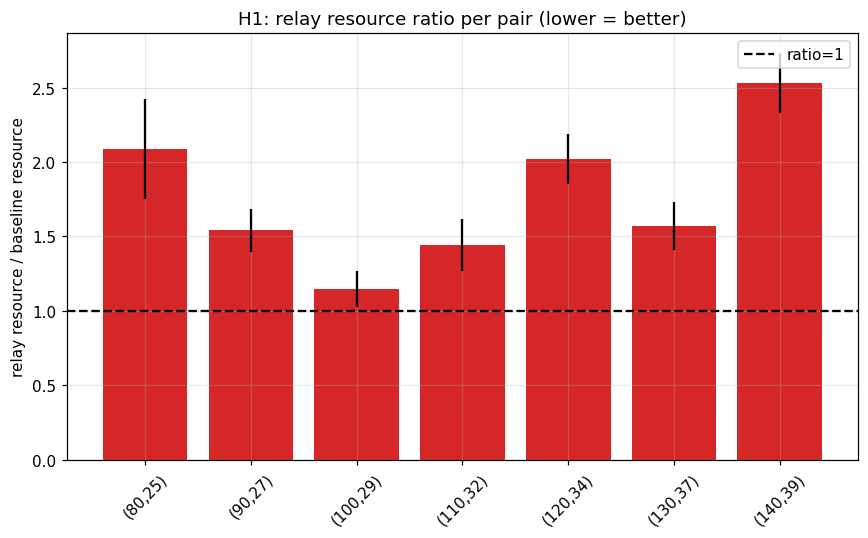

In [7]:
# Placeholder: Wilcoxon paired by seed.
from scipy.stats import wilcoxon
if phase3_compare is not None:
    # baseline and relay rows are joined on (speed,ivd,seed) by aggregate
    cols = ['total_subch_slots','prr_worst','prr_mean','pir_p95_ms','aoi_peak_ms']
    for col in cols:
        diffs = phase3_compare[f'{col}_relay'] - phase3_compare[f'{col}_baseline']
        # Wilcoxon only on non-zero diffs (scipy needs >0)
        nz = diffs[diffs != 0]
        if len(nz) >= 5:
            stat, p = wilcoxon(nz)
            print(f'  {col}: median diff = {diffs.median():+.3f}  Wilcoxon p = {p:.4f}')
        else:
            print(f'  {col}: too few nonzero diffs (n={len(nz)}); skip Wilcoxon')
    # Resource ratio per pair
    phase3_compare['res_ratio'] = (phase3_compare['total_subch_slots_relay']
                                    / phase3_compare['total_subch_slots_baseline'])
    pair_res = phase3_compare.groupby(['speed','ivd']).res_ratio.agg(['mean','median','std'])
    display(pair_res)
    # H1 verdict: relay saves resource when ratio < 1
    n_relay_saves = (pair_res['mean'] < 1.0).sum()
    n_pairs = len(pair_res)
    print(f'H1: relay saves resource on {n_relay_saves}/{n_pairs} pairs')
    fig, ax = plt.subplots()
    ax.bar(range(len(pair_res)), pair_res['mean'], yerr=pair_res['std'],
           color=['C2' if m<1 else 'C3' for m in pair_res['mean']])
    ax.axhline(1.0, color='k', linestyle='--', label='ratio=1')
    ax.set_xticks(range(len(pair_res)))
    ax.set_xticklabels([f'({s},{i})' for s,i in pair_res.index], rotation=45)
    ax.set_ylabel('relay resource / baseline resource')
    ax.set_title('H1: relay resource ratio per pair (lower = better)')
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print('Phase 3 data not yet available.')


In [8]:
# Placeholder: render the H1-H4 verdict table.
import pandas as pd
if phase3_compare is not None:
    # Aggregate by pair to a verdict per pair.
    rows = []
    for (speed, ivd), grp in phase3_compare.groupby(['speed','ivd']):
        h1 = (grp.total_subch_slots_relay < grp.total_subch_slots_baseline).mean()
        h2 = (grp.prr_worst_relay >= grp.prr_worst_baseline - 0.005).mean()
        h3 = (grp.pir_p95_ms_relay <= grp.pir_p95_ms_baseline + 1.0).mean()
        h4 = (grp.psr_relay >= 0.99).mean() if grp.psr_relay.notna().any() else None
        rows.append({'speed': speed, 'ivd': ivd,
                     'H1_resource_win': round(h1, 2),
                     'H2_reliability_>=': round(h2, 2),
                     'H3_latency_<=': round(h3, 2),
                     'H4_psr_gate': round(h4, 2) if h4 is not None else None})
    verdict = pd.DataFrame(rows)
    display(verdict)
else:
    print('Phase 3 data not yet available.')


,speed,ivd,H1_resource_win,H2_reliability_>=,H3_latency_<=,H4_psr_gate
0,80,25,0.0,0.0,0.4,1.0
1,90,27,0.0,0.7,1.0,1.0
2,100,29,0.1,0.5,0.8,1.0
3,110,32,0.0,0.8,0.6,1.0
4,120,34,0.0,0.2,0.8,1.0
5,130,37,0.0,0.4,0.7,1.0
6,140,39,0.0,0.4,0.9,1.0


## 7. Summary

Filled in once all 4 phases have run. Headline:
- R-A: MCS×distance surface and m*_i.
- R-B: r* per pair.
- R-C: latency model coefficients.
- R-D: storm-free MCD per pair.
- H1-H4: paired Wilcoxon verdict across pairs.